# Apache Spark - Stroke Tutorial

En este taller se trabaja con un conjunto de datos de pacientes con y sin derrame cerebral. Con PySpark preparamos los datos, revisamos sus distribuciones y comparamos cuatro modelos de clasificación de Spark MLlib sobre el mismo conjunto de prueba.

**Andres Felipe Diaz Torres**
* Procesamiento de datos a gran escala
* 09/09/2026
* Profesor: John Corredor
* Institucion: PUJ

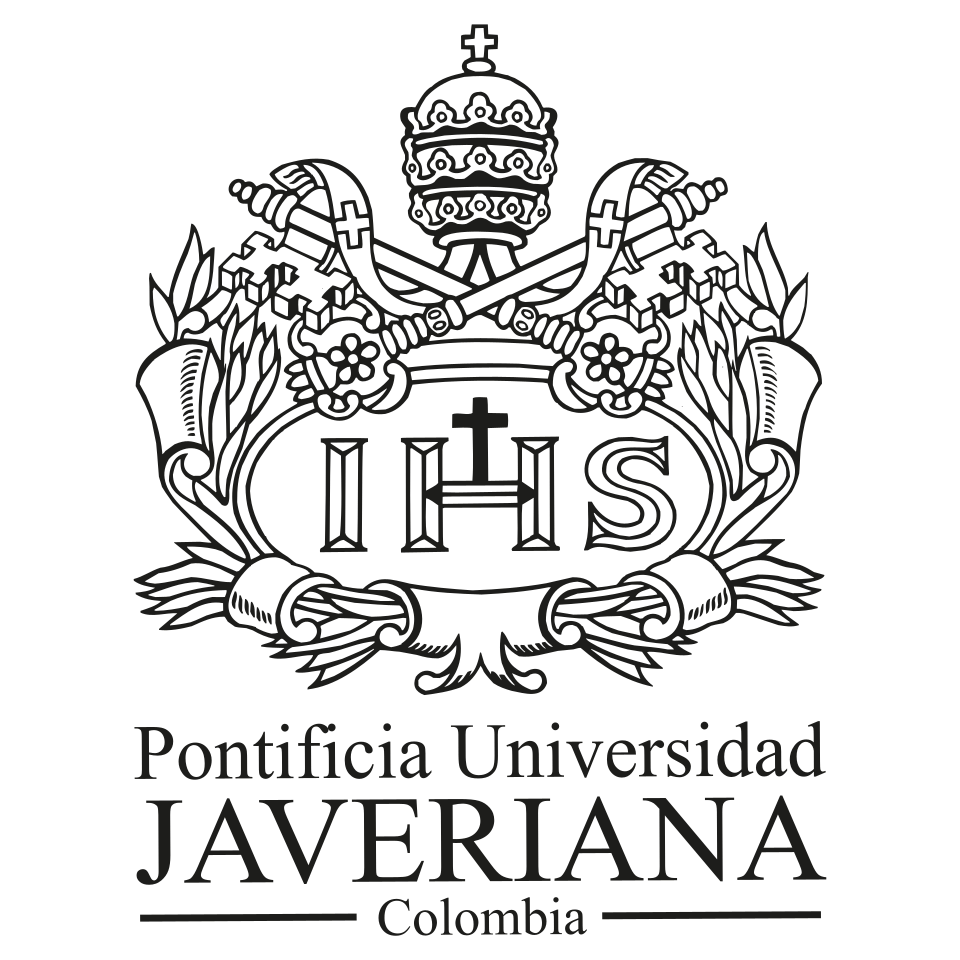

## Objetivos

**Objetivo general.** Preparar los datos de pacientes y comparar cuatro modelos de clasificación de Spark MLlib para identificar registros con derrame cerebral (Derrame = 1).

**Objetivos específicos**

- Explorar las variables y preparar los datos mediante el ajuste de tipos, el tratamiento de valores faltantes y la codificación de categorías.
- Evaluar los modelos sobre el mismo conjunto de prueba y comparar cuántos derrames detectan, cuántos omiten y cuántas falsas alarmas generan.

## Importing Libraries

In [1]:
# Generic Libraries
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

#Apache Spark libraries
import findspark
findspark.init('/mnt/sda1/Cluster/Spark')

# Apache Spark Libraries
import pyspark
from pyspark.sql import SparkSession

# Apache Spark ML Classifier Libraries
from pyspark.ml.classification import DecisionTreeClassifier, RandomForestClassifier, NaiveBayes

# Apache Spark Evaluation Library
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Apache Spark Features libraries
from pyspark.ml.feature import StandardScaler, StringIndexer, VectorAssembler, VectorIndexer, OneHotEncoder

# Apache Spark Pipeline Library
from pyspark.ml import Pipeline

# Apache Spark DenseVector
from pyspark.ml.linalg import DenseVector

# Data Split Libraries
import sklearn
from sklearn.model_selection import train_test_split


# Garbage
import gc


In [2]:
### Bibliotecas adicionales
#Biblioteca para estadística/inferencia/probabilidades y pintar
import seaborn as sns
#Biblioteca para pintar
import matplotlib.pyplot as plt
#Adicionales
from pyspark import SparkConf
from pyspark.sql import SparkSession
### Bibliotecas faltantes
from pyspark.sql import functions as F

## Build Spark Session

In [3]:
#Building Spark Session
configura = SparkConf().set("spark.ui.port","37007")
configura.setAppName("DiazTallerStroke")
#Sesion y contexto
sparkDiaz = SparkSession.builder.config(conf=configura).getOrCreate()
#SQLContext(sparkContext=sparkDiaz, sparkSession=sparkDiaz)
sparkContextoDiaz = sparkDiaz.sparkContext.getOrCreate()
sparkDiaz

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


## Data Load

### **1.-Diágnostico y Tratamiento de Datos
- Cambio de nombres de columnas (features)
- Tipos y coherencia de datos
- Identificación y tratamiento de datos/nulos/atipicos
- Estadística de los datos
- Tratamiento de columnas categoricas

In [4]:
# Se observa la carpeta csv del datalake HADOOP
#La idea es usar el dataset desde HADOOP para no traerlo local
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /csv

Found 11 items
drwxr-xr-x   - sistemas supergroup          0 2026-10-23 13:39 /csv/BankMarketing
-rw-r--r--   2 sistemas supergroup     977501 2026-03-10 15:27 /csv/CustomerChurn.csv
-rw-r--r--   2 sistemas supergroup      40868 2025-07-07 15:41 /csv/Fortune500USCompanies.csv
drwxr-xr-x   - sistemas supergroup          0 2025-10-16 14:17 /csv/auxiliar
drwxr-xr-x   - sistemas supergroup          0 2026-11-12 12:16 /csv/calidadAgua
-rw-r--r--   2 sistemas supergroup      34635 2025-09-02 13:22 /csv/jugadores.csv
-rw-r--r--   2 sistemas supergroup    1082023 2025-09-02 13:22 /csv/resultados_futbol.csv
-rw-r--r--   2 sistemas supergroup     316971 2025-06-10 09:11 /csv/stroke_pyspark.csv
drwxr-xr-x   - sistemas supergroup          0 2025-06-18 15:36 /csv/taxi
drwxr-xr-x   - sistemas supergroup          0 2026-04-23 15:56 /csv/titanic
-rw-r--r--   2 sistemas supergroup      84199 2026-04-23 17:11 /csv/winequality-red.csv


In [5]:
# Se carga el dataset spark_stroke.csv a la sesión actual de trabajo.

url = "hdfs://10.195.34.34:9000/csv/stroke_pyspark.csv"
df00 = sparkDiaz.read.format("csv").option("header", "true").load(url)
df00.show(5)

[Stage 1:>                                                          (0 + 1) / 1]

+-----+------+---+------------+-------------+------------+-------------+--------------+-----------------+----+---------------+------+
|   id|gender|age|hypertension|heart_disease|ever_married|    work_type|Residence_type|avg_glucose_level| bmi| smoking_status|stroke|
+-----+------+---+------------+-------------+------------+-------------+--------------+-----------------+----+---------------+------+
| 9046|  Male| 67|           0|            1|         Yes|      Private|         Urban|           228.69|36.6|formerly smoked|     1|
|51676|Female| 61|           0|            0|         Yes|Self-employed|         Rural|           202.21| N/A|   never smoked|     1|
|31112|  Male| 80|           0|            1|         Yes|      Private|         Rural|           105.92|32.5|   never smoked|     1|
|60182|Female| 49|           0|            0|         Yes|      Private|         Urban|           171.23|34.4|         smokes|     1|
| 1665|Female| 79|           1|            0|         Yes|Self

In [6]:
# Se visualizan los nombres originales de las columnas
df00.columns

['id',
 'gender',
 'age',
 'hypertension',
 'heart_disease',
 'ever_married',
 'work_type',
 'Residence_type',
 'avg_glucose_level',
 'bmi',
 'smoking_status',
 'stroke']

In [7]:
nuevosNombre = ['id','Genero','Edad','Hipertension','EnfCardiaco','Casado','Tipotrabajo','Tiporesidencia','PromNivelGlucosa','BMI','Fumador','Derrame']

### Se cambia por los nuevos nombre
df01 = df00
for antes, nuevo in zip(df00.columns, nuevosNombre):
    df01 = df01.withColumnRenamed(antes,nuevo)

df01.columns

['id',
 'Genero',
 'Edad',
 'Hipertension',
 'EnfCardiaco',
 'Casado',
 'Tipotrabajo',
 'Tiporesidencia',
 'PromNivelGlucosa',
 'BMI',
 'Fumador',
 'Derrame']

In [8]:
#Cantidad total de datos
df01.count()

5110

In [9]:
#Tipos de datos
df01.printSchema()

root
 |-- id: string (nullable = true)
 |-- Genero: string (nullable = true)
 |-- Edad: string (nullable = true)
 |-- Hipertension: string (nullable = true)
 |-- EnfCardiaco: string (nullable = true)
 |-- Casado: string (nullable = true)
 |-- Tipotrabajo: string (nullable = true)
 |-- Tiporesidencia: string (nullable = true)
 |-- PromNivelGlucosa: string (nullable = true)
 |-- BMI: string (nullable = true)
 |-- Fumador: string (nullable = true)
 |-- Derrame: string (nullable = true)



In [10]:
### Edad: string se cambia a entero
df02 = df01.withColumn("Edad", df01.Edad.cast("int"))
### Hipertension: string se castea a entero
df02 = df02.withColumn("Hipertension", df01.Hipertension.cast("int"))
### EnfCardiaco: string se castea a entero
df02 = df02.withColumn("EnfCardiaco", df01.EnfCardiaco.cast("int"))
### BMI: string se castea a double
df02 = df02.withColumn("BMI", df01.BMI.cast("double"))
### Derrame: string se castea a entero
df02 = df02.withColumn("Derrame", df01.Derrame.cast("int"))
### PromNivelGlucosa: string se castea a double
df02 = df02.withColumn("PromNivelGlucosa", df01.PromNivelGlucosa.cast("double"))
### Genero: string se mantiene como string
df02 = df02.withColumn("Genero", df01.Genero.cast("string"))

In [11]:
#Mostrar datos
df02.printSchema()

root
 |-- id: string (nullable = true)
 |-- Genero: string (nullable = true)
 |-- Edad: integer (nullable = true)
 |-- Hipertension: integer (nullable = true)
 |-- EnfCardiaco: integer (nullable = true)
 |-- Casado: string (nullable = true)
 |-- Tipotrabajo: string (nullable = true)
 |-- Tiporesidencia: string (nullable = true)
 |-- PromNivelGlucosa: double (nullable = true)
 |-- BMI: double (nullable = true)
 |-- Fumador: string (nullable = true)
 |-- Derrame: integer (nullable = true)



In [12]:
#Identificación y tratamiento de datos/nulos/atipicos
df02.select([F.count(F.when(F.isnan(c) | F.col(c).isNull(), c)).alias(c) for c in df02.columns]).show()

+---+------+----+------------+-----------+------+-----------+--------------+----------------+---+-------+-------+
| id|Genero|Edad|Hipertension|EnfCardiaco|Casado|Tipotrabajo|Tiporesidencia|PromNivelGlucosa|BMI|Fumador|Derrame|
+---+------+----+------------+-----------+------+-----------+--------------+----------------+---+-------+-------+
|  0|     0|   0|           0|          0|     0|          0|             0|               0|201|      0|      0|
+---+------+----+------------+-----------+------+-----------+--------------+----------------+---+-------+-------+



In [13]:
# Se listan las columnas del dataframe df02
df02.columns

['id',
 'Genero',
 'Edad',
 'Hipertension',
 'EnfCardiaco',
 'Casado',
 'Tipotrabajo',
 'Tiporesidencia',
 'PromNivelGlucosa',
 'BMI',
 'Fumador',
 'Derrame']

In [14]:
# Tener cuidado a la hora de reemplazar nulos ya que si es un numero muy alto puede afectar y no se pueden dejar vacíos así que se reemplaza por promedios,
# en grupos de edad y genero, podría hacerse con plazos de edad menores (5 años) para ser más cercanos
nulosBMI = (201/df02.count())*100
print(f"El procentaje de nulos es =  {nulosBMI} %")

El procentaje de nulos es =  3.9334637964774952 %


In [15]:
# Para el 4% de datos de BMI, se ajusta para no eliminarlos.
# Se saca el promedio de BMI para cambiarlos
# El promedio se hara por edades y por genero
# La estratificacion se hara por decadas

In [16]:
# Promedio de BMI por female y cada 10 años
avg10f = df02.where((F.col("Genero") == F.lit("Female")) & (F.col("Edad") <= 10)).select(F.mean(F.col("BMI"))).collect()
avg20f = df02.where((F.col("Genero") == F.lit("Female")) & (F.col("Edad") > 10) & (F.col("Edad") <= 20)).select(F.mean(F.col("BMI"))).collect()
avg30f = df02.where((F.col("Genero") == F.lit("Female")) & (F.col("Edad") > 20) & (F.col("Edad") <= 30)).select(F.mean(F.col("BMI"))).collect()
avg40f = df02.where((F.col("Genero") == F.lit("Female")) & (F.col("Edad") > 30) & (F.col("Edad") <= 40)).select(F.mean(F.col("BMI"))).collect()
avg50f = df02.where((F.col("Genero") == F.lit("Female")) & (F.col("Edad") > 40) & (F.col("Edad") <= 50)).select(F.mean(F.col("BMI"))).collect()
avg60f = df02.where((F.col("Genero") == F.lit("Female")) & (F.col("Edad") > 50) & (F.col("Edad") <= 60)).select(F.mean(F.col("BMI"))).collect()
avg70f = df02.where((F.col("Genero") == F.lit("Female")) & (F.col("Edad") > 60) & (F.col("Edad") <= 70)).select(F.mean(F.col("BMI"))).collect()
avg80f = df02.where((F.col("Genero") == F.lit("Female")) & (F.col("Edad") > 70) & (F.col("Edad") <= 80)).select(F.mean(F.col("BMI"))).collect()
avg90f = df02.where((F.col("Genero") == F.lit("Female")) & (F.col("Edad") > 80) & (F.col("Edad") <= 90)).select(F.mean(F.col("BMI"))).collect()
avg100f = df02.where((F.col("Genero") == F.lit("Female")) & (F.col("Edad") > 90)).select(F.mean(F.col("BMI"))).collect()

In [17]:
#Se imprimen los promedios femeninos
print(f"Promedio de 10 años feminas = {round(avg10f[0][0],2)} de BMI")
print(f"Promedio de 20 años feminas = {round(avg20f[0][0],2)} de BMI")
print(f"Promedio de 30 años feminas = {round(avg30f[0][0],2)} de BMI")
print(f"Promedio de 40 años feminas = {round(avg40f[0][0],2)} de BMI")
print(f"Promedio de 50 años feminas = {round(avg50f[0][0],2)} de BMI")
print(f"Promedio de 60 años feminas = {round(avg60f[0][0],2)} de BMI")
print(f"Promedio de 70 años feminas = {round(avg70f[0][0],2)} de BMI")
print(f"Promedio de 80 años feminas = {round(avg80f[0][0],2)} de BMI")
print(f"Promedio de 90 años feminas = {round(avg90f[0][0],2)} de BMI")

Promedio de 10 años feminas = 18.72 de BMI
Promedio de 20 años feminas = 25.52 de BMI
Promedio de 30 años feminas = 28.64 de BMI
Promedio de 40 años feminas = 31.17 de BMI
Promedio de 50 años feminas = 30.94 de BMI
Promedio de 60 años feminas = 31.92 de BMI
Promedio de 70 años feminas = 30.72 de BMI
Promedio de 80 años feminas = 29.23 de BMI
Promedio de 90 años feminas = 28.1 de BMI


In [18]:
# Promedio de BMI por male y cada 10 años
avg10M = df02.where((F.col("Genero") == F.lit("Male")) & (F.col("Edad") <= 10)).select(F.mean(F.col("BMI"))).collect()
avg20M = df02.where((F.col("Genero") == F.lit("Male")) & (F.col("Edad") > 10) & (F.col("Edad") <= 20)).select(F.mean(F.col("BMI"))).collect()
avg30M = df02.where((F.col("Genero") == F.lit("Male")) & (F.col("Edad") > 20) & (F.col("Edad") <= 30)).select(F.mean(F.col("BMI"))).collect()
avg40M = df02.where((F.col("Genero") == F.lit("Male")) & (F.col("Edad") > 30) & (F.col("Edad") <= 40)).select(F.mean(F.col("BMI"))).collect()
avg50M = df02.where((F.col("Genero") == F.lit("Male")) & (F.col("Edad") > 40) & (F.col("Edad") <= 50)).select(F.mean(F.col("BMI"))).collect()
avg60M = df02.where((F.col("Genero") == F.lit("Male")) & (F.col("Edad") > 50) & (F.col("Edad") <= 60)).select(F.mean(F.col("BMI"))).collect()
avg70M = df02.where((F.col("Genero") == F.lit("Male")) & (F.col("Edad") > 60) & (F.col("Edad") <= 70)).select(F.mean(F.col("BMI"))).collect()
avg80M = df02.where((F.col("Genero") == F.lit("Male")) & (F.col("Edad") > 70) & (F.col("Edad") <= 80)).select(F.mean(F.col("BMI"))).collect()
avg90M = df02.where((F.col("Genero") == F.lit("Male")) & (F.col("Edad") > 80) & (F.col("Edad") <= 90)).select(F.mean(F.col("BMI"))).collect()
avg100M = df02.where((F.col("Genero") == F.lit("Male")) & (F.col("Edad") > 90)).select(F.mean(F.col("BMI"))).collect()

In [19]:
#Se imprimen los promedios masculinos
print(f"Promedio de 10 años Male = {round(avg10M[0][0],2)} de BMI")
print(f"Promedio de 20 años Male = {round(avg20M[0][0],2)} de BMI")
print(f"Promedio de 30 años Male = {round(avg30M[0][0],2)} de BMI")
print(f"Promedio de 40 años Male = {round(avg40M[0][0],2)} de BMI")
print(f"Promedio de 50 años Male = {round(avg50M[0][0],2)} de BMI")
print(f"Promedio de 60 años Male = {round(avg60M[0][0],2)} de BMI")
print(f"Promedio de 70 años Male = {round(avg70M[0][0],2)} de BMI")
print(f"Promedio de 80 años Male = {round(avg80M[0][0],2)} de BMI")
print(f"Promedio de 90 años Male = {round(avg90M[0][0],2)} de BMI")

Promedio de 10 años Male = 19.1 de BMI
Promedio de 20 años Male = 25.25 de BMI
Promedio de 30 años Male = 28.31 de BMI
Promedio de 40 años Male = 31.33 de BMI
Promedio de 50 años Male = 32.21 de BMI
Promedio de 60 años Male = 31.85 de BMI
Promedio de 70 años Male = 31.28 de BMI
Promedio de 80 años Male = 29.0 de BMI
Promedio de 90 años Male = 27.81 de BMI


In [20]:
#Generos presentes en el dataset
df02.groupby(['Genero']).count().show()

+------+-----+
|Genero|count|
+------+-----+
|Female| 2994|
| Other|    1|
|  Male| 2115|
+------+-----+



In [21]:
#Se descarta el other
df02 = df02.where("Genero <> 'Other'")

In [22]:
#Generos presentes en el dataset sin other
df02.groupby(['Genero']).count().show()

+------+-----+
|Genero|count|
+------+-----+
|Female| 2994|
|  Male| 2115|
+------+-----+



In [23]:
#Respuestas presentes en el dataset, sobre si esta casado o no
df02.groupby(['Casado']).count().show()
# No se modifica ya que solo salio si o no

+------+-----+
|Casado|count|
+------+-----+
|    No| 1756|
|   Yes| 3353|
+------+-----+



In [24]:
# Respuestas presentes en el dataset, sobre si ha trabajado o no
df02.groupby(['Tipotrabajo']).count().show()
# No hay valores huerfanos, se deja de esa manera

+-------------+-----+
|  Tipotrabajo|count|
+-------------+-----+
| Never_worked|   22|
|Self-employed|  819|
|      Private| 2924|
|     children|  687|
|     Govt_job|  657|
+-------------+-----+



In [25]:
# Respuestas presentes en el dataset, sobre su tipo de residencia
df02.groupby(['Tiporesidencia']).count().show()
# Se dejan los dos valores de urbano y rural no requiere modificación

+--------------+-----+
|Tiporesidencia|count|
+--------------+-----+
|         Urban| 2596|
|         Rural| 2513|
+--------------+-----+



In [26]:
# Respuestas presentes en el dataset, sobre si ha fumado o no
df02.groupby(['Fumador']).count().show()
# No hay que realizar ajuste de datos

+---------------+-----+
|        Fumador|count|
+---------------+-----+
|         smokes|  789|
|        Unknown| 1544|
|   never smoked| 1892|
|formerly smoked|  884|
+---------------+-----+



In [27]:
#Reemplazo en un nuevo dataframe el promedio de edades de los Female
df03 = df02.withColumn("BMI", F.when((df02["Genero"] == 'Female') & (df02["BMI"].isNull() & (df02["Edad"] <= 10)), round(avg10f[0][0],2)).otherwise(df02["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female') & (df03["BMI"].isNull() & (df03["Edad"] > 10)) & (df03["Edad"] <= 20), round(avg20f[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female') & (df03["BMI"].isNull() & (df03["Edad"] > 20)) & (df03["Edad"] <= 30), round(avg30f[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female') & (df03["BMI"].isNull() & (df03["Edad"] > 30)) & (df03["Edad"] <= 40), round(avg40f[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female') & (df03["BMI"].isNull() & (df03["Edad"] > 40)) & (df03["Edad"] <= 50), round(avg50f[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female') & (df03["BMI"].isNull() & (df03["Edad"] > 50)) & (df03["Edad"] <= 60), round(avg60f[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female') & (df03["BMI"].isNull() & (df03["Edad"] > 60)) & (df03["Edad"] <= 70), round(avg70f[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female') & (df03["BMI"].isNull() & (df03["Edad"] > 70)) & (df03["Edad"] <= 80), round(avg80f[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female') & (df03["BMI"].isNull() & (df03["Edad"] > 80)) & (df03["Edad"] <= 90), round(avg90f[0][0],2)).otherwise(df03["BMI"]))

In [28]:
#Reemplazo en un nuevo dataframe el promedio de edades de los Male
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male') & (df03["BMI"].isNull() & (df03["Edad"] <= 10)), round(avg10M[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male') & (df03["BMI"].isNull() & (df03["Edad"] > 10)) & (df03["Edad"] <= 20), round(avg20M[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male') & (df03["BMI"].isNull() & (df03["Edad"] > 20)) & (df03["Edad"] <= 30), round(avg30M[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male') & (df03["BMI"].isNull() & (df03["Edad"] > 30)) & (df03["Edad"] <= 40), round(avg40M[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male') & (df03["BMI"].isNull() & (df03["Edad"] > 40)) & (df03["Edad"] <= 50), round(avg50M[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male') & (df03["BMI"].isNull() & (df03["Edad"] > 50)) & (df03["Edad"] <= 60), round(avg60M[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male') & (df03["BMI"].isNull() & (df03["Edad"] > 60)) & (df03["Edad"] <= 70), round(avg70M[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male') & (df03["BMI"].isNull() & (df03["Edad"] > 70)) & (df03["Edad"] <= 80), round(avg80M[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male') & (df03["BMI"].isNull() & (df03["Edad"] > 80)) & (df03["Edad"] <= 90), round(avg90M[0][0],2)).otherwise(df03["BMI"]))

In [29]:
# Verificación de datos nulos o atípicos (se les reemplazó por la media en rangos)
df03.select([F.count(F.when(F.isnan(c) | F.col(c).isNull(), c)).alias(c) for c in df03.columns]).show()

+---+------+----+------------+-----------+------+-----------+--------------+----------------+---+-------+-------+
| id|Genero|Edad|Hipertension|EnfCardiaco|Casado|Tipotrabajo|Tiporesidencia|PromNivelGlucosa|BMI|Fumador|Derrame|
+---+------+----+------------+-----------+------+-----------+--------------+----------------+---+-------+-------+
|  0|     0|   0|           0|          0|     0|          0|             0|               0|  0|      0|      0|
+---+------+----+------------+-----------+------+-----------+--------------+----------------+---+-------+-------+



## Informacion general de Objeto Dataframe PySpark

In [30]:
# Estadísticas descriptivas del dataframe df03
df03.describe().show()

26/11/15 16:58:22 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
[Stage 92:>                                                         (0 + 1) / 1]

+-------+------------------+------+-----------------+-------------------+-------------------+------+-----------+--------------+------------------+------------------+-------+-------------------+
|summary|                id|Genero|             Edad|       Hipertension|        EnfCardiaco|Casado|Tipotrabajo|Tiporesidencia|  PromNivelGlucosa|               BMI|Fumador|            Derrame|
+-------+------------------+------+-----------------+-------------------+-------------------+------+-----------+--------------+------------------+------------------+-------+-------------------+
|  count|              5109|  5109|             5109|               5109|               5109|  5109|       5109|          5109|              5109|              5109|   5109|               5109|
|   mean| 36513.98551575651|  NULL|43.21863378351928|0.09747504403992954| 0.0540223135642983|  NULL|       NULL|          NULL|106.14039929536098| 28.91596007046389|   NULL|0.04873752201996477|
| stddev|21162.008804347086|  

## Gráficas de los datos

In [31]:
### Para usar seaborn se hace cambio a objeto pandas
datosIctus = df03.toPandas()

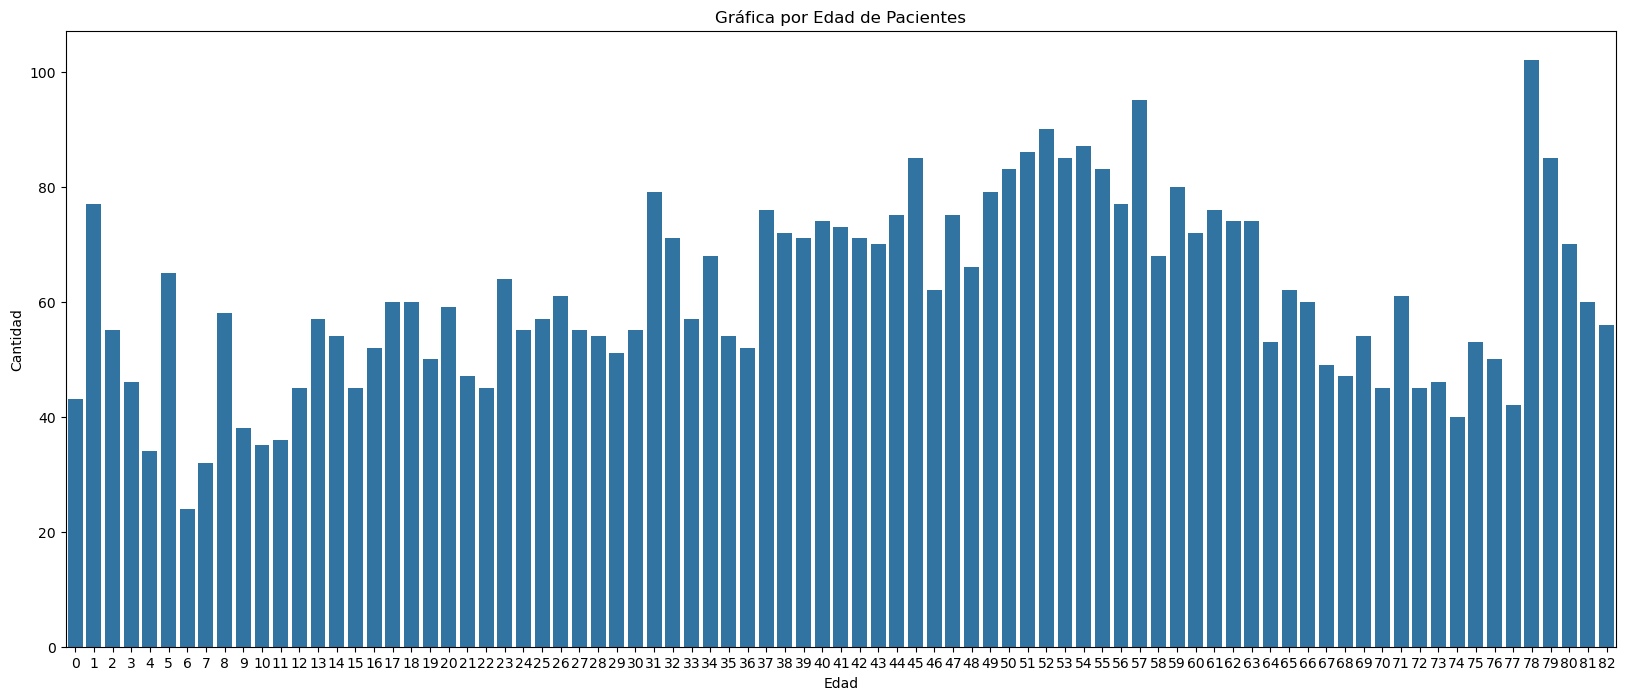

In [32]:
# Grafica de cantidad por edad
plt.figure(figsize=(20, 8))
sns.countplot(x = 'Edad', data= datosIctus)
plt.title("Gráfica por Edad de Pacientes")
plt.ylabel("Cantidad")
plt.show()

**Análisis:** En la gráfica se observan pacientes desde los 0 hasta los 82 años de edad. Las edades con mayor cantidad de personas están alrededor de los 57 años y entre los 78 y 79 años, superando los 100 pacientes en esos puntos. En cambio, en los primeros años de vida y cerca de los 10 años es donde se registran menos pacientes por edad.

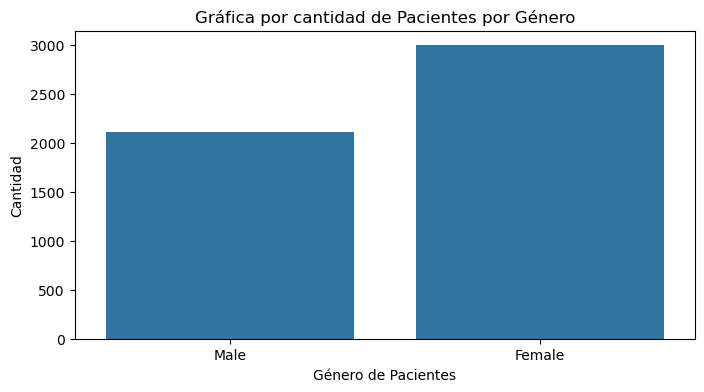

In [33]:
# Grafica de cantidad por Genero
plt.figure(figsize=(8, 4))
sns.countplot(data=datosIctus, x = 'Genero')
plt.title("Gráfica por cantidad de Pacientes por Género")
plt.xlabel("Género de Pacientes")
plt.ylabel("Cantidad")
plt.show()

**Análisis:** Se observa que en el grupo de datos hay más mujeres (Female) que hombres (Male). En total se registran 2994 mujeres frente a 2115 hombres después de haber quitado el único registro Other. Esto muestra una diferencia clara de casi 900 pacientes más del género femenino.

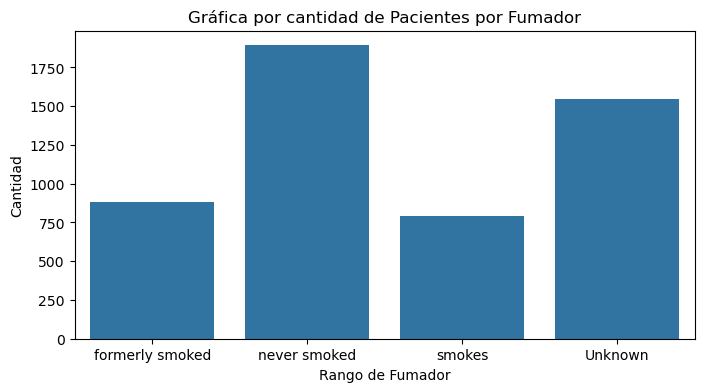

In [34]:
# Grafica de cantidad de Fumadores
plt.figure(figsize=(8, 4))
sns.countplot(data=datosIctus, x = 'Fumador')
plt.title("Gráfica por cantidad de Pacientes por Fumador")
plt.xlabel("Rango de Fumador")
plt.ylabel("Cantidad")
plt.show()

**Análisis:** El grupo más grande corresponde a las personas que nunca han fumado (never smoked), con cerca de 1900 pacientes. En segundo lugar aparece el grupo sin información (Unknown) con más de 1500 registros. Los grupos con menos personas son los que fumaron antes (formerly smoked) y los que fuman actualmente (smokes), ambos por debajo de los 900 pacientes.

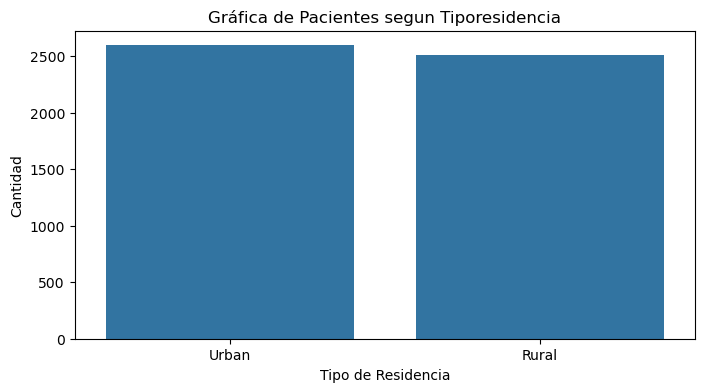

In [35]:
# Grafica de cantidad de pacientes segun tiporesidencia
plt.figure(figsize=(8, 4))
sns.countplot(data=datosIctus, x = 'Tiporesidencia')
plt.title("Gráfica de Pacientes segun Tiporesidencia")
plt.xlabel("Tipo de Residencia")
plt.ylabel("Cantidad")
plt.show()

**Análisis:** La cantidad de pacientes que viven en zona urbana (Urban) y en zona rural (Rural) es casi igual. El grupo urbano tiene 2596 personas y el grupo rural cuenta con 2513 personas. Por lo tanto, los datos están repartidos de forma muy pareja entre ambos tipos de residencia.

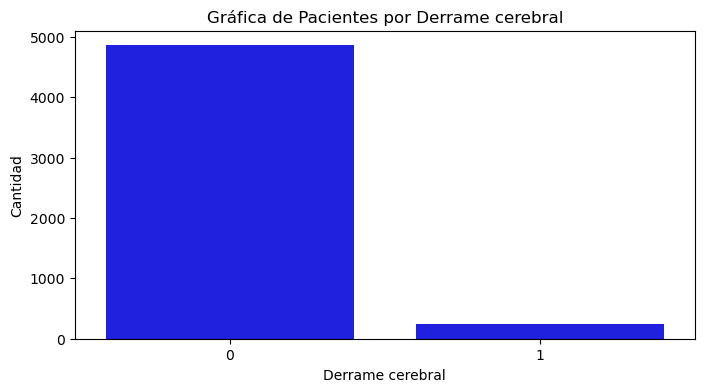

In [36]:
# Grafica de cantidad por Ictus
plt.figure(figsize=(8, 4))
sns.countplot(data=datosIctus, x = 'Derrame', color='blue')
plt.title("Gráfica de Pacientes por Derrame cerebral")
plt.xlabel("Derrame cerebral")
plt.ylabel("Cantidad")
plt.show()

**Análisis:** En la gráfica se ve una gran diferencia entre los pacientes que no tuvieron derrame (0) y los que sí lo tuvieron (1). Casi todos los registros están en el valor 0, superando los 4800 pacientes. Solo una pequeña parte, alrededor de 250 personas, presenta un derrame cerebral (1).

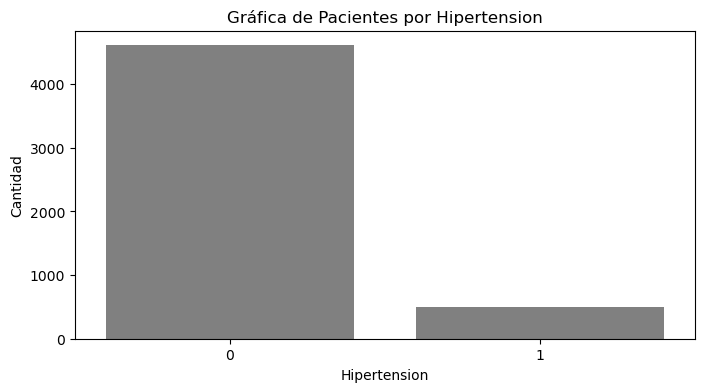

In [37]:
# Grafica por cantidad de pacientes por hipertension
plt.figure(figsize=(8, 4))
sns.countplot(data=datosIctus, x = 'Hipertension', color='gray')
plt.title("Gráfica de Pacientes por Hipertension")
plt.xlabel("Hipertension")
plt.ylabel("Cantidad")
plt.show()

**Análisis:** La gran mayoría de los pacientes evaluados se ubica en el valor 0, lo que indica que no tienen hipertensión. Este grupo principal supera los 4600 registros dentro de la muestra. Por otro lado, los pacientes que sí tienen hipertensión (1) son cerca de 500 personas.

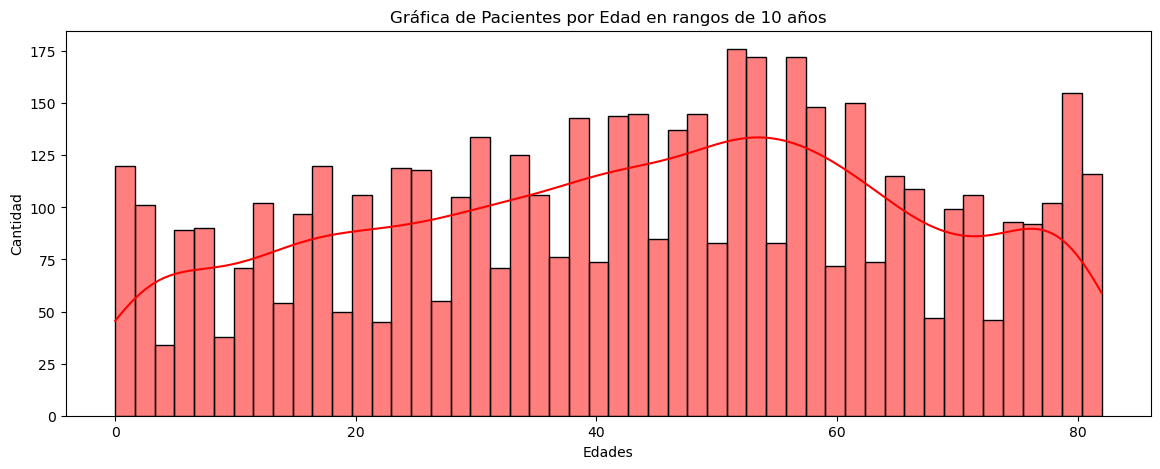

In [38]:
# Histograma de cantidad de pacientes por edad
plt.figure(figsize=(14, 5))
sns.histplot(data=datosIctus, x ='Edad', bins=50, kde=True, color='red' )
plt.title("Gráfica de Pacientes por Edad en rangos de 10 años")
plt.xlabel("Edades")
plt.ylabel("Cantidad")
plt.show()

**Análisis:** La distribución muestra que hay pacientes en todas las edades, desde recién nacidos hasta el límite de 82 años. La curva sube y concentra la mayor cantidad de personas entre los 40 y los 60 años, además de tener otro pico alto cerca de los 80 años. Hacia las edades menores de 20 años la cantidad de registros es más baja y estable.

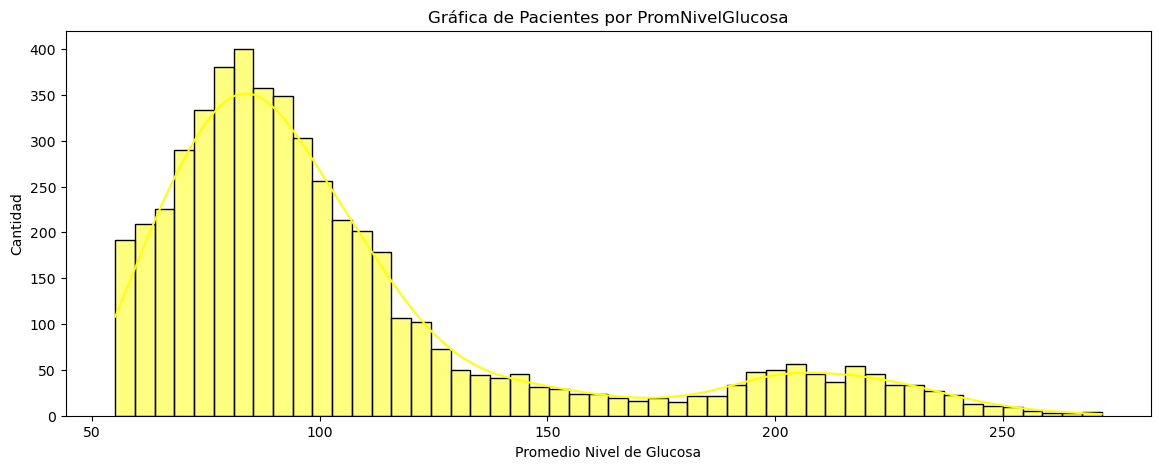

In [39]:
# Grafica por cantidad de pacientes por PromNivelGlucosa
plt.figure(figsize=(14, 5))
sns.histplot(data=datosIctus, x ='PromNivelGlucosa', bins=50, kde=True, color='yellow' )
plt.title("Gráfica de Pacientes por PromNivelGlucosa")
plt.xlabel("Promedio Nivel de Glucosa")
plt.ylabel("Cantidad")
plt.show()

**Análisis:** La mayor parte de los pacientes tiene un nivel promedio de glucosa concentrado entre 60 y 120. Después de ese rango la cantidad de personas baja bastante entre los valores de 130 y 180. Finalmente, se ve un segundo grupo mucho más pequeño de pacientes con niveles altos de glucosa entre 190 y 250.

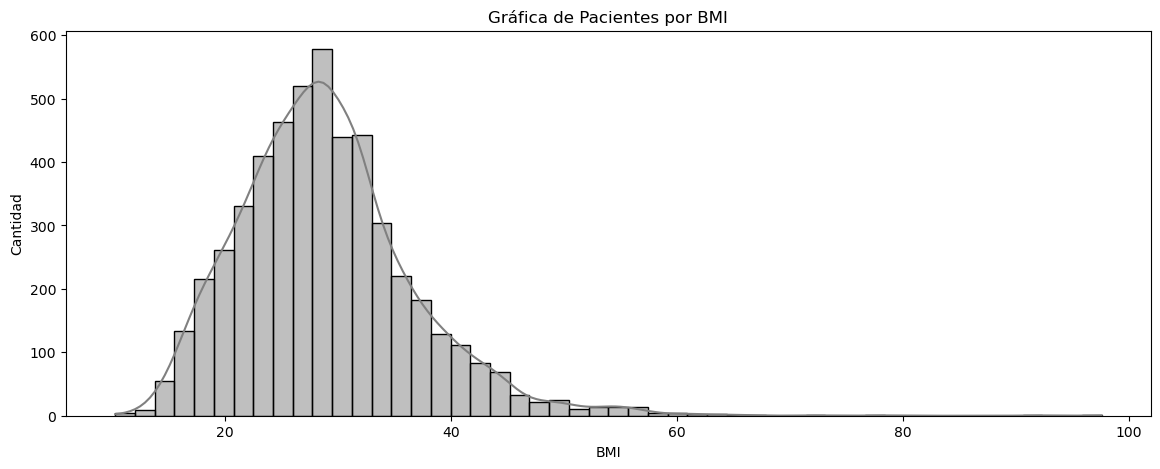

In [40]:
# Grafica por cantidad de pacientes por BMI
plt.figure(figsize=(14, 5))
sns.histplot(data=datosIctus, x ='BMI', bins=50, kde=True, color='gray' )
plt.title("Gráfica de Pacientes por BMI")
plt.xlabel("BMI")
plt.ylabel("Cantidad")
plt.show()

**Análisis:** La mayoría de los pacientes tiene un índice de masa corporal (BMI) ubicado entre 20 y 35, donde se forma el pico principal de la gráfica. Hacia la derecha la curva baja rápido, mostrando pocos casos a partir de un valor de 50. También se observan algunos valores aislados muy altos que llegan hasta casi 98.

## Se requiere una gráfica de promedio de nivel de glucosa según el derrame cerebral

<Figure size 1700x400 with 0 Axes>

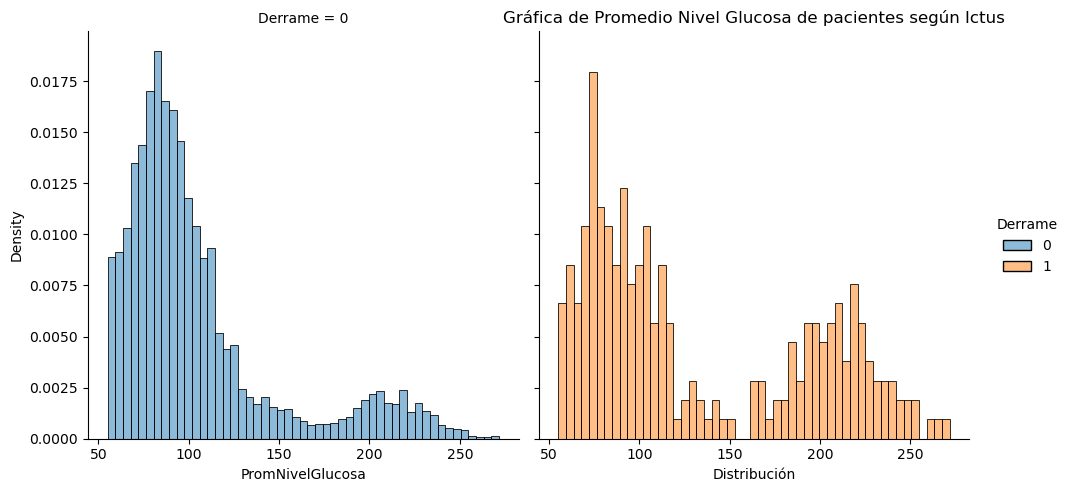

In [41]:
# Grafica por densidad de PromNivelGlucosa según derrame cerebral
plt.figure(figsize=(17, 4))
sns.displot(data=datosIctus, x ='PromNivelGlucosa', hue= 'Derrame', col='Derrame', stat='density', common_norm=False )
plt.title("Gráfica de Promedio Nivel Glucosa de pacientes según Ictus")
plt.xlabel("Distribución")
plt.ylabel("Densidad")
plt.show()

**Análisis:** En la gráfica de la izquierda (Derrame = 0), casi todos los pacientes sin derrame tienen su nivel de glucosa entre 60 y 120, y muy pocos pasan de 180. En cambio, en la gráfica de la derecha (Derrame = 1), aunque también hay muchos pacientes entre 60 y 120, el segundo pico entre 190 y 240 crece bastante. Esto deja ver que en el grupo que sufrió derrame hay una mayor proporción de personas con glucosa alta que en el grupo sin derrame.

In [42]:
# Grafica de BMI por edades
plt.figure(figsize=(8, 4))
sns.displot(data=datosIctus, x ='BMI', hue= 'Edad', col='Edad', stat='density', common_norm=False )
plt.title("Gráfica de BMI por edades según Ictus")
plt.xlabel("Distribución")
plt.ylabel("Densidad")
plt.show()

<Figure size 800x400 with 0 Axes>

**Análisis:** La figura divide los datos en una gráfica separada para cada edad desde 0 hasta 82 años para mostrar cómo se reparte el BMI. En las primeras edades los valores de BMI se concentran más a la izquierda (valores más bajos), mientras que en las edades adultas se desplazan hacia el centro. Al estar separada en 83 cuadros distintos, cada gráfica individual tiene pocos datos y muestra picos altos en valores específicos.

## Observaciones de Edad con Ictus

### Se observa alto riesgo de ICTUS en personas mayores de 40 años

In [43]:
### Se requiere agregar una nueva columna que tenga pacientes con alto riesgo
df04 = df03.withColumn('AltoRiesgo', F.when((F.col('Edad')>=40) & (F.col('PromNivelGlucosa')<=125), 1).otherwise(0))
df04.show(5)

+-----+------+----+------------+-----------+------+-------------+--------------+----------------+-----+---------------+-------+----------+
|   id|Genero|Edad|Hipertension|EnfCardiaco|Casado|  Tipotrabajo|Tiporesidencia|PromNivelGlucosa|  BMI|        Fumador|Derrame|AltoRiesgo|
+-----+------+----+------------+-----------+------+-------------+--------------+----------------+-----+---------------+-------+----------+
| 9046|  Male|  67|           0|          1|   Yes|      Private|         Urban|          228.69| 36.6|formerly smoked|      1|         0|
|51676|Female|  61|           0|          0|   Yes|Self-employed|         Rural|          202.21|30.72|   never smoked|      1|         0|
|31112|  Male|  80|           0|          1|   Yes|      Private|         Rural|          105.92| 32.5|   never smoked|      1|         1|
|60182|Female|  49|           0|          0|   Yes|      Private|         Urban|          171.23| 34.4|         smokes|      1|         0|
| 1665|Female|  79|        

In [44]:
# Se verifica el esquema con la nueva columna AltoRiesgo
df04.printSchema()

root
 |-- id: string (nullable = true)
 |-- Genero: string (nullable = true)
 |-- Edad: integer (nullable = true)
 |-- Hipertension: integer (nullable = true)
 |-- EnfCardiaco: integer (nullable = true)
 |-- Casado: string (nullable = true)
 |-- Tipotrabajo: string (nullable = true)
 |-- Tiporesidencia: string (nullable = true)
 |-- PromNivelGlucosa: double (nullable = true)
 |-- BMI: double (nullable = true)
 |-- Fumador: string (nullable = true)
 |-- Derrame: integer (nullable = true)
 |-- AltoRiesgo: integer (nullable = false)



# Graficas en funcion de alto riesgo

### Alto riesgo vs derrame cerebral & Enfermedad cardiaca

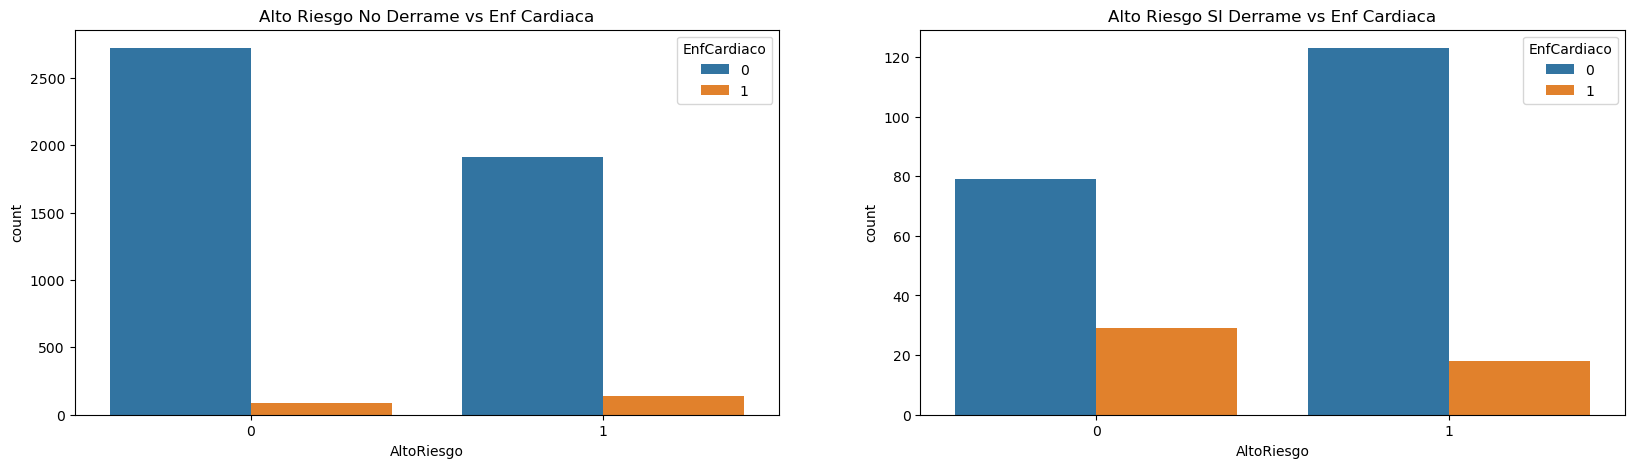

In [45]:
### Para usar seaborn se hace cambio a objeto pandas
datosPandas = df04.toPandas()

## Se requiere una matriz de 1x2
fig, matrix = plt.subplots(1, 2, figsize=(20,5))

matrix[0].set_title("Alto Riesgo No Derrame vs Enf Cardiaca")
matrix0 = sns.countplot(data=datosPandas.loc[datosPandas['Derrame']==0], 
                        x='AltoRiesgo', hue='EnfCardiaco', ax=matrix[0])

matrix[1].set_title("Alto Riesgo SI Derrame vs Enf Cardiaca")
matrix1 = sns.countplot(data=datosPandas.loc[datosPandas['Derrame']==1], 
                        x='AltoRiesgo', hue='EnfCardiaco', ax=matrix[1])

**Análisis:** Entre quienes no tuvieron derrame (Derrame = 0), predominan los pacientes sin enfermedad cardíaca en ambos grupos. Entre quienes sí tuvieron derrame (Derrame = 1), el grupo marcado por la regla (AltoRiesgo = 1) tiene cerca de 140 pacientes en total, algo más de 120 sin enfermedad cardíaca y cerca de 18 con ella.

### Alto riesgo vs derrame cerebral & Hipertensión

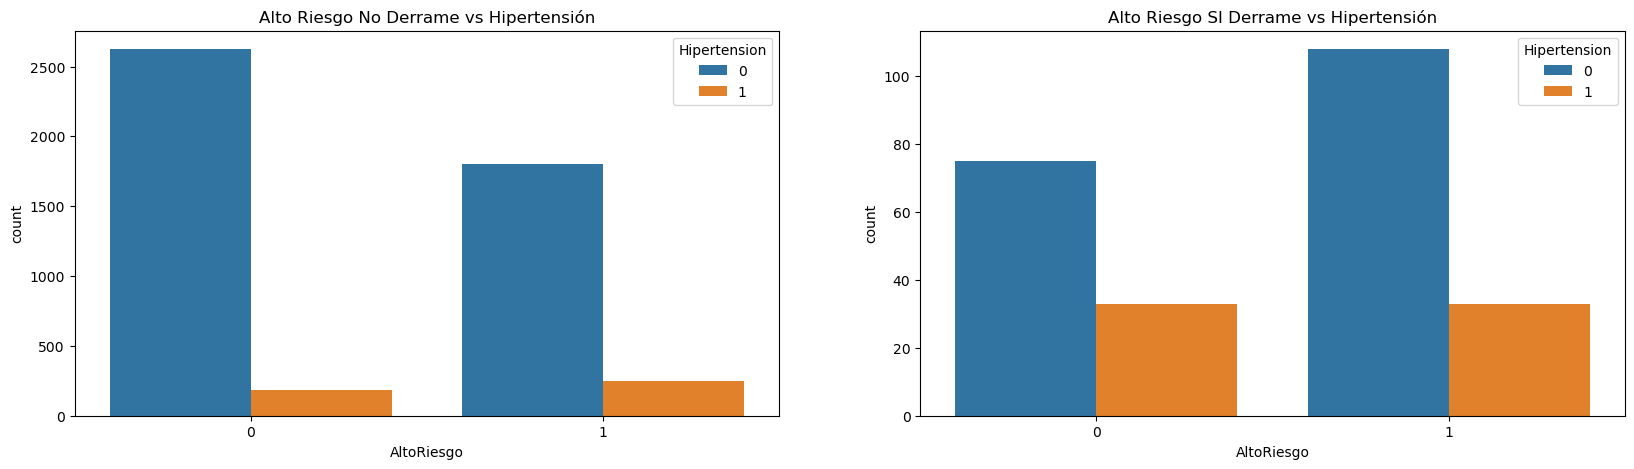

In [46]:
### Para usar seaborn se hace cambio a objeto pandas
datosPandas = df04.toPandas()

## Se requiere una matriz de 1x2
fig, matrix = plt.subplots(1, 2, figsize=(20,5))

matrix[0].set_title("Alto Riesgo No Derrame vs Hipertensión")
matrix0 = sns.countplot(data=datosPandas.loc[datosPandas['Derrame']==0], 
                        x='AltoRiesgo', hue='Hipertension', ax=matrix[0])

matrix[1].set_title("Alto Riesgo SI Derrame vs Hipertensión")
matrix1 = sns.countplot(data=datosPandas.loc[datosPandas['Derrame']==1], 
                        x='AltoRiesgo', hue='Hipertension', ax=matrix[1])

**Análisis:** Entre quienes no tuvieron derrame (Derrame = 0), hay más pacientes con hipertensión en el grupo marcado por la regla (AltoRiesgo = 1). Entre quienes sí tuvieron derrame (Derrame = 1), hay cerca de 33 pacientes con hipertensión en cada grupo. En el grupo marcado por la regla (AltoRiesgo = 1), cerca de 108 no tenían hipertensión.

### Alto riesgo vs derrame cerebral & Fumador

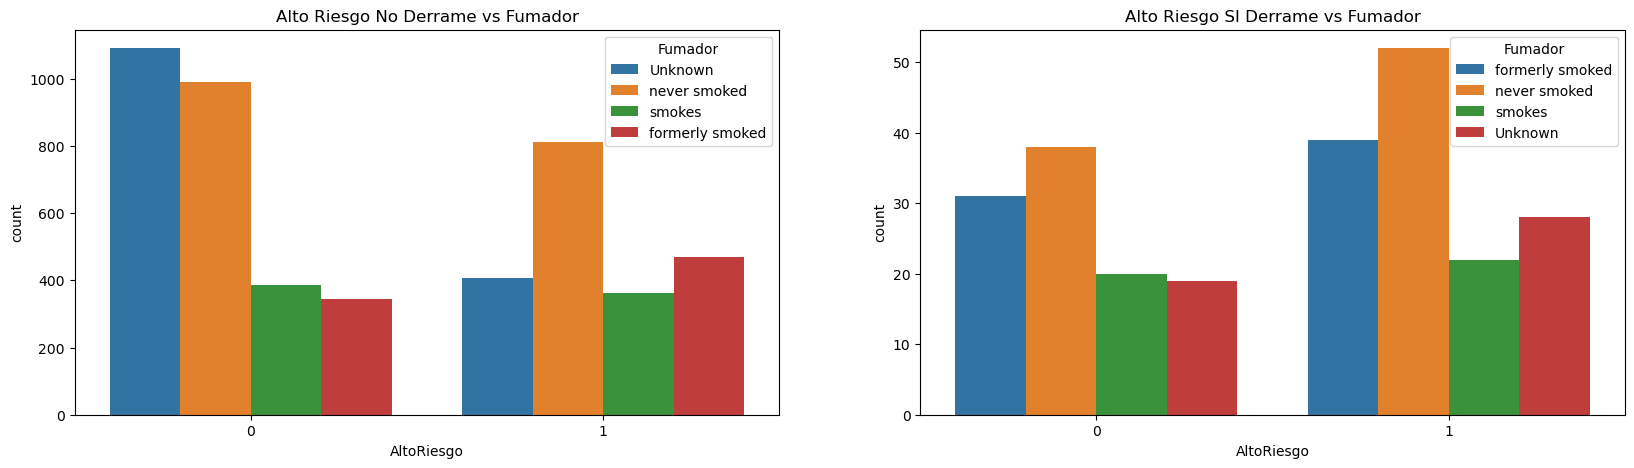

In [47]:
### Para usar seaborn se hace cambio a objeto pandas
datosPandas = df04.toPandas()

## Se requiere una matriz de 1x2
fig, matrix = plt.subplots(1, 2, figsize=(20,5))

matrix[0].set_title("Alto Riesgo No Derrame vs Fumador")
matrix0 = sns.countplot(data=datosPandas.loc[datosPandas['Derrame']==0], 
                        x='AltoRiesgo', hue='Fumador', ax=matrix[0])

matrix[1].set_title("Alto Riesgo SI Derrame vs Fumador")
matrix1 = sns.countplot(data=datosPandas.loc[datosPandas['Derrame']==1], 
                        x='AltoRiesgo', hue='Fumador', ax=matrix[1])

**Análisis:** Entre quienes no tuvieron derrame (Derrame = 0), en el grupo que no cumple la regla (AltoRiesgo = 0) predominan los registros sin información sobre tabaquismo. Entre quienes sí tuvieron derrame (Derrame = 1) y cumplen la regla (AltoRiesgo = 1), cerca de 52 nunca fumaron y 39 fumaron antes. Cada panel se lee con su propia leyenda, porque algunos colores cambian de significado.

### Alto riesgo vs derrame cerebral & Estado Civil

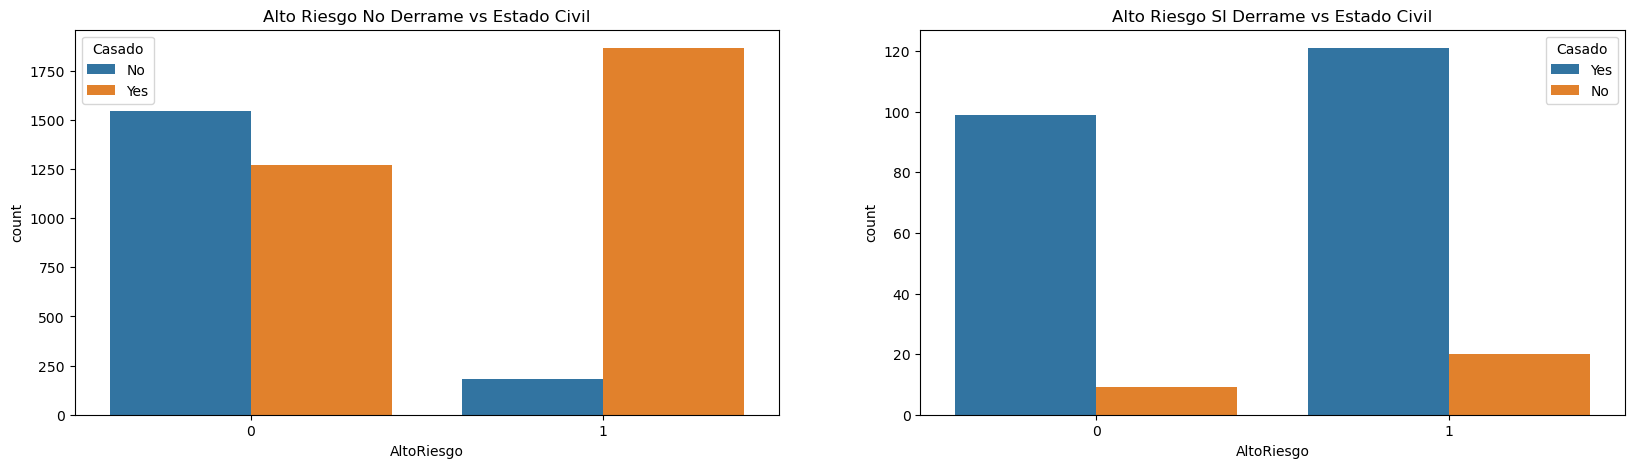

In [48]:
### Para usar seaborn se hace cambio a objeto pandas
datosPandas = df04.toPandas()

## Se requiere una matriz de 1x2
fig, matrix = plt.subplots(1, 2, figsize=(20,5))

matrix[0].set_title("Alto Riesgo No Derrame vs Estado Civil")
matrix0 = sns.countplot(data=datosPandas.loc[datosPandas['Derrame']==0], 
                        x='AltoRiesgo', hue='Casado', ax=matrix[0])

matrix[1].set_title("Alto Riesgo SI Derrame vs Estado Civil")
matrix1 = sns.countplot(data=datosPandas.loc[datosPandas['Derrame']==1], 
                        x='AltoRiesgo', hue='Casado', ax=matrix[1])

**Análisis:** En la gráfica de la izquierda (sin derrame), en el grupo sin alto riesgo hay más personas no casadas (No), mientras que en el grupo de alto riesgo la gran mayoría sí está casada (Yes), debido a que el alto riesgo filtra personas de 40 años o más. En la gráfica de la derecha (con derrame), casi todos los pacientes están casados (Yes), especialmente en el grupo de alto riesgo (AltoRiesgo = 1). Los pacientes no casados (No) que sufrieron derrame representan una cantidad muy baja en comparación con los casados.

In [49]:
# Se verifica el esquema de columnas
df04.printSchema()

root
 |-- id: string (nullable = true)
 |-- Genero: string (nullable = true)
 |-- Edad: integer (nullable = true)
 |-- Hipertension: integer (nullable = true)
 |-- EnfCardiaco: integer (nullable = true)
 |-- Casado: string (nullable = true)
 |-- Tipotrabajo: string (nullable = true)
 |-- Tiporesidencia: string (nullable = true)
 |-- PromNivelGlucosa: double (nullable = true)
 |-- BMI: double (nullable = true)
 |-- Fumador: string (nullable = true)
 |-- Derrame: integer (nullable = true)
 |-- AltoRiesgo: integer (nullable = false)



In [50]:
### Se imprime el nombre de las columnas
df04.columns

['id',
 'Genero',
 'Edad',
 'Hipertension',
 'EnfCardiaco',
 'Casado',
 'Tipotrabajo',
 'Tiporesidencia',
 'PromNivelGlucosa',
 'BMI',
 'Fumador',
 'Derrame',
 'AltoRiesgo']

In [51]:
### Se separan las variables categoricas
noCategorias = ['Edad','Hipertension','EnfCardiaco','PromNivelGlucosa','BMI','Derrame','AltoRiesgo']
### Se realiza los indices en funcion de su posicion [0,1,2,...]
indices = [StringIndexer(inputCol=variable, outputCol=variable+"_IND").fit(df04)
            for variable in list(set(df04.columns) - set(noCategorias))]

### Se realiza la tubería para la etapa de cambio de categoria a numericos
tuberia = Pipeline(stages=indices)
### Se crea una nueva version
df05 = tuberia.fit(df04).transform(df04)

### Se borran las columnas con variables categoricas
varCategoricas = ['id','Genero','Casado','Tipotrabajo','Tiporesidencia','Fumador']
df05 = df05.drop(*varCategoricas)
### Mostrar como quedo
df05.show(5)

+----+------------+-----------+----------------+-----+-------+----------+----------+------------------+-----------+----------+------+---------------+
|Edad|Hipertension|EnfCardiaco|PromNivelGlucosa|  BMI|Derrame|AltoRiesgo|Genero_IND|Tiporesidencia_IND|Fumador_IND|Casado_IND|id_IND|Tipotrabajo_IND|
+----+------------+-----------+----------------+-----+-------+----------+----------+------------------+-----------+----------+------+---------------+
|  67|           0|          1|          228.69| 36.6|      1|         0|       1.0|               0.0|        2.0|       0.0|5052.0|            0.0|
|  61|           0|          0|          202.21|30.72|      1|         0|       0.0|               1.0|        0.0|       0.0|3218.0|            1.0|
|  80|           0|          1|          105.92| 32.5|      1|         1|       1.0|               1.0|        0.0|       0.0|1593.0|            0.0|
|  49|           0|          0|          171.23| 34.4|      1|         0|       0.0|               0

Explicación: Se usa la tubería (Pipeline) porque permite agrupar y aplicar todos los StringIndexer de las variables de texto en un solo paso ordenado sobre el DataFrame, en lugar de transformar columna por columna manualmente. Como alternativa se podría aplicar cada StringIndexer por separado o usar OneHotEncoder para crear columnas binarias. Además, se borran las columnas originales de texto porque los modelos matemáticos de Spark MLlib solo pueden hacer cálculos con valores numéricos y no reciben cadenas de texto como entrada.

In [52]:
### Se retira el id_IND
df05 = df05.drop("id_IND")
### Mostrar como quedo
df05.show(5)

+----+------------+-----------+----------------+-----+-------+----------+----------+------------------+-----------+----------+---------------+
|Edad|Hipertension|EnfCardiaco|PromNivelGlucosa|  BMI|Derrame|AltoRiesgo|Genero_IND|Tiporesidencia_IND|Fumador_IND|Casado_IND|Tipotrabajo_IND|
+----+------------+-----------+----------------+-----+-------+----------+----------+------------------+-----------+----------+---------------+
|  67|           0|          1|          228.69| 36.6|      1|         0|       1.0|               0.0|        2.0|       0.0|            0.0|
|  61|           0|          0|          202.21|30.72|      1|         0|       0.0|               1.0|        0.0|       0.0|            1.0|
|  80|           0|          1|          105.92| 32.5|      1|         1|       1.0|               1.0|        0.0|       0.0|            0.0|
|  49|           0|          0|          171.23| 34.4|      1|         0|       0.0|               0.0|        3.0|       0.0|            0.0|

Observación: La preparación de los datos no ha sido del todo satisfactoria , se debe realizar mejor estudio sobre todo de los outiliers o comportamientos atipicos, entre otros.

## Implementación de Modelos de Machine Learning usando MLib

- Creación de vectores de caracteríosticas
- División de datos para entrenamiento y prueba(prueba = 20% de los datos)
- Se ejecutan los modelos seleccionados
- Se evaluan los modelos con las métricas de rendimiento

## Creación de caracteristicas vector de variables independientes

In [53]:
## Se realiza el vector de variables independientes
varIndependientes = VectorAssembler(inputCols=df05.drop('Derrame').columns, outputCol='independientes')

vectorIndependientes = varIndependientes.transform(df05).select('independientes', 'Derrame')

### Mostrar como quedo
vectorIndependientes.show(10, False)

+--------------------------------------------------+-------+
|independientes                                    |Derrame|
+--------------------------------------------------+-------+
|(11,[0,2,3,4,6,8],[67.0,1.0,228.69,36.6,1.0,2.0]) |1      |
|(11,[0,3,4,7,10],[61.0,202.21,30.72,1.0,1.0])     |1      |
|[80.0,0.0,1.0,105.92,32.5,1.0,1.0,1.0,0.0,0.0,0.0]|1      |
|(11,[0,3,4,8],[49.0,171.23,34.4,3.0])             |1      |
|(11,[0,1,3,4,7,10],[79.0,1.0,174.12,24.0,1.0,1.0])|1      |
|(11,[0,3,4,6,8],[81.0,186.21,29.0,1.0,2.0])       |1      |
|[74.0,1.0,1.0,70.09,27.4,1.0,1.0,1.0,0.0,0.0,0.0] |1      |
|(11,[0,3,4,5,9],[69.0,94.39,22.8,1.0,1.0])        |1      |
|(11,[0,3,4,5,7,8],[59.0,76.15,31.92,1.0,1.0,1.0]) |1      |
|(11,[0,3,4,5,8],[78.0,58.57,24.2,1.0,1.0])        |1      |
+--------------------------------------------------+-------+
only showing top 10 rows



Explicación: En Spark MLlib es obligatorio unir todas las variables de entrada en una sola columna de tipo vector (usando VectorAssembler) porque los algoritmos de aprendizaje esperan recibir un único parámetro con el vector de características (featuresCol) junto con la columna objetivo que se quiere predecir (labelCol).

In [54]:
## Mostrar columnas
vectorIndependientes.columns

['independientes', 'Derrame']

## División de datos para entrenamiento y prueba

In [55]:
### Se crea un dataframe spark desde el vector
df06 = vectorIndependientes.select(['independientes', 'Derrame'])

# train = conjunto de entrenamiento 80% de los datos
# test = conjunto para prueba 20% de los datos
train, test = df06.randomSplit([0.8,0.2])

In [56]:
### Se requiere revisar el porcentaje de "Derrame" en el conjunto de entrenamiento (train)
totalTrain = float(train.select('Derrame').count())
conDerrameTrain = train.select('Derrame').where('Derrame == 1').count()

porcentajeConDerrameTrain = (float(conDerrameTrain)/float(totalTrain))*100
noDerrameTrain = float(totalTrain-conDerrameTrain)
print(f"Cantidad de Con Derrame en conjunto de entrenamiento = {conDerrameTrain}")
print(f"Porcentaje de Con Derrame en conjunto de entrenamiento = {round(porcentajeConDerrameTrain,2)}%")

Cantidad de Con Derrame en conjunto de entrenamiento = 202
Porcentaje de Con Derrame en conjunto de entrenamiento = 4.87%


**Observación sobre el desbalance de datos.** En esta corrida, 202 pacientes del conjunto de entrenamiento tenían registrado un derrame (4,87 %). En el conjunto de prueba hubo 47 pacientes con derrame y 915 sin derrame. Por eso se revisa la sensibilidad para (Derrame = 1) junto con la precisión y los falsos positivos.

## **Se aplican los modelos seleccionados**

- Regresión Logística
- Naive Bayes
- Árboles de Decisión
- Random Forest

### Lectura de las matrices de confusión

Las filas corresponden al diagnóstico registrado y las columnas a la predicción. Se calculan los conteos sobre el mismo conjunto de prueba para los cuatro modelos. La sensibilidad mide qué proporción de los pacientes con derrame (Derrame = 1) fue detectada. La precisión mide qué proporción de los casos que el modelo marcó como (Derrame = 1) tenía registrado ese diagnóstico.

In [57]:
def evaluar_deteccion(predicciones, nombre_modelo):
    conteos = {
        (int(fila["Derrame"]), int(fila["prediction"])): fila["count"]
        for fila in predicciones.groupBy("Derrame", "prediction").count().collect()
    }
    vn = conteos.get((0, 0), 0)
    fp = conteos.get((0, 1), 0)
    fn = conteos.get((1, 0), 0)
    vp = conteos.get((1, 1), 0)

    fig, ax = plt.subplots(figsize=(5.5, 4))
    etiquetas = ["Sin derrame (0)", "Con derrame (1)"]
    sns.heatmap([[vn, fp], [fn, vp]], annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=etiquetas, yticklabels=etiquetas, ax=ax)
    ax.set(title=f"Matriz de confusión — {nombre_modelo}",
           xlabel="Predicción del modelo", ylabel="Resultado observado")
    ax.tick_params(axis="y", rotation=0)
    fig.tight_layout()
    plt.show()

    casos_reales = vp + fn
    casos_predichos = vp + fp
    sensibilidad = 100 * vp / casos_reales if casos_reales else None
    precision = 100 * vp / casos_predichos if casos_predichos else None
    return {
        "Modelo": nombre_modelo,
        "Casos reales de derrame": casos_reales,
        "Derrames detectados (VP)": vp,
        "Derrames omitidos (FN)": fn,
        "Falsas alarmas (FP)": fp,
        "Sin derrame bien clasificados (VN)": vn,
        "Sensibilidad para derrame (%)": sensibilidad,
        "Precisión para derrame (%)": precision,
    }

### 1. Modelo de Regresión Logística

Se eligió como modelo de referencia para estimar la probabilidad de un resultado binario (Derrame = 0 o 1). Permite comparar la detección de derrames con técnicas que usan reglas de decisión.

In [58]:
from pyspark.ml.classification import LogisticRegression

## Se instancia el modelo de regresión logística
RegreLog = LogisticRegression(featuresCol='independientes', labelCol='Derrame')
## Se aplica el modelo de regresión logística sobre los datos de entrenamiento
modeloRegLog = RegreLog.fit(train)

## Se evalúa el modelo de Regresión Logística
- Curva AUC-ROC: Mide la capacidad del modelo para distinguir entre pacientes con derrame (1) y sin derrame (0) (un valor más cercano a 1 indica mejor separación).
- Accuracy (Exactitud): Porcentaje total de predicciones correctas sobre el conjunto de prueba.
- Precision (Precisión ponderada): Qué proporción de las predicciones realizadas para cada clase fue realmente correcta.
- Recall (sensibilidad ponderada): Promedio de la sensibilidad de las clases, ponderado por la cantidad real de casos de cada una. La matriz de confusión permite revisar por separado la sensibilidad para (Derrame = 1).

In [59]:
### Se hacen las predicciones sobre los datos de prueba en el modelo de RL
predRLog = modeloRegLog.transform(test)
## Se toman las probabilidades de resultados
resultadosRLog = predRLog.select(['probability', 'Derrame'])
## Se colectan los resultados
coleccResultadosRLog = resultadosRLog.collect()
## Se genera una lista
resultListaRLog = [(float(i[0][0]), 1.0 - float(i[1])) for i in coleccResultadosRLog]

## Se realizan las puntuaciones
puntuacionRLog = sparkContextoDiaz.parallelize(resultListaRLog)

In [60]:
#### Impresión de métricas sobre resultados de prueba
from pyspark.mllib.evaluation import BinaryClassificationMetrics as Metricas
metricasRlog = Metricas(puntuacionRLog)
## Curva AUC
ACURlog = metricasRlog.areaUnderROC
acurracyRlog = MulticlassClassificationEvaluator(labelCol='Derrame', metricName='accuracy').evaluate(predRLog)
precisRlog = MulticlassClassificationEvaluator(labelCol='Derrame', metricName='weightedPrecision').evaluate(predRLog)
recallRlog = MulticlassClassificationEvaluator(labelCol='Derrame', metricName='weightedRecall').evaluate(predRLog)

/mnt/sda1/Cluster/Spark/python/pyspark/sql/context.py:158: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


In [61]:
## Se imprimen las métricas con dos decimales
print(f"AUC-ROC : {round(ACURlog, 2)}")
print(f"Accuracy : {round(acurracyRlog, 2)}")
print(f"Precision : {round(precisRlog, 2)}")
print(f"Recall : {round(recallRlog, 2)}")

AUC-ROC : 0.84
Accuracy : 0.95
Precision : 0.9
Recall : 0.95


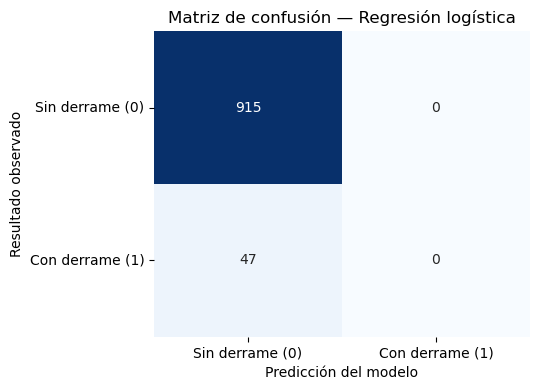

In [62]:
medicion_rl = evaluar_deteccion(predRLog, "Regresión logística")

De 47 pacientes con derrame (Derrame = 1), el modelo detectó 0 y dejó pasar los 47. Clasificó correctamente a los 915 pacientes sin derrame (Derrame = 0) y no generó falsas alarmas. El modelo no cumplió el objetivo de detección porque no logró identificar ningún caso de derrame.

### 2. Modelo de Naive Bayes

Se incluyó como referencia probabilística. Permite observar cómo se comporta un modelo que combina las características bajo un supuesto de independencia condicional dada la clase.

In [63]:
from pyspark.ml.classification import NaiveBayes

## Se instancia el modelo de Naive Bayes
nb = NaiveBayes(featuresCol='independientes', labelCol='Derrame')
## Se aplica el modelo de Naive Bayes sobre los datos de entrenamiento
modeloNB = nb.fit(train)

## Se evalúa el modelo de Naive Bayes

In [64]:
### Se hacen las predicciones sobre los datos de prueba en el modelo de Naive Bayes
predNB = modeloNB.transform(test)
## Se toman las probabilidades de resultados
resultadosNB = predNB.select(['probability', 'Derrame'])
## Se colectan los resultados
coleccResultadosNB = resultadosNB.collect()
## Se genera una lista
resultListaNB = [(float(i[0][0]), 1.0 - float(i[1])) for i in coleccResultadosNB]

## Se realizan las puntuaciones
puntuacionNB = sparkContextoDiaz.parallelize(resultListaNB)

#### Cálculo e impresión de métricas sobre resultados de prueba
metricasNB = Metricas(puntuacionNB)
ACUNB = metricasNB.areaUnderROC
accuracyNB = MulticlassClassificationEvaluator(labelCol='Derrame', metricName='accuracy').evaluate(predNB)
precisNB = MulticlassClassificationEvaluator(labelCol='Derrame', metricName='weightedPrecision').evaluate(predNB)
recallNB = MulticlassClassificationEvaluator(labelCol='Derrame', metricName='weightedRecall').evaluate(predNB)

print(f"AUC-ROC : {round(ACUNB, 2)}")
print(f"Accuracy : {round(accuracyNB, 2)}")
print(f"Precision : {round(precisNB, 2)}")
print(f"Recall : {round(recallNB, 2)}")

/mnt/sda1/Cluster/Spark/python/pyspark/sql/context.py:158: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


AUC-ROC : 0.77
Accuracy : 0.79
Precision : 0.93
Recall : 0.79


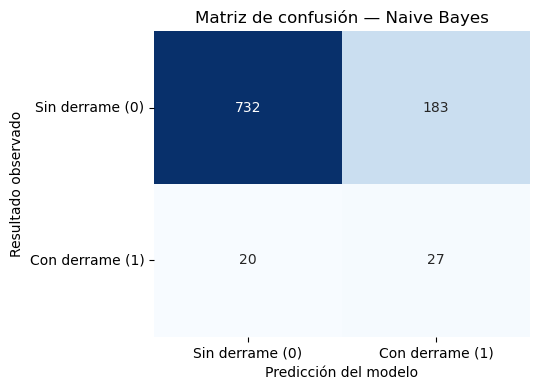

In [65]:
medicion_nb = evaluar_deteccion(predNB, "Naive Bayes")

De 47 pacientes con derrame (Derrame = 1), el modelo detectó 27 y dejó pasar 20. Entre los 915 pacientes sin derrame (Derrame = 0), clasificó correctamente a 732 y generó 183 falsas alarmas.

### 3. Modelo de Árboles de Decisión

Se eligió porque puede combinar variables mediante reglas sucesivas. El árbol permite seguir las divisiones que llevan a clasificar un registro como (Derrame = 0) o (Derrame = 1).

In [66]:
from pyspark.ml.classification import DecisionTreeClassifier

## Se instancia el modelo de Árbol de Decisión
dt = DecisionTreeClassifier(featuresCol='independientes', labelCol='Derrame')
## Se aplica el modelo de Árbol de Decisión sobre los datos de entrenamiento
modeloDT = dt.fit(train)

## Se evalúa el modelo de Árboles de Decisión

In [67]:
### Se hacen las predicciones sobre los datos de prueba en el modelo de Árbol de Decisión
predDT = modeloDT.transform(test)
## Se toman las probabilidades de resultados
resultadosDT = predDT.select(['probability', 'Derrame'])
## Se colectan los resultados
coleccResultadosDT = resultadosDT.collect()
## Se genera una lista
resultListaDT = [(float(i[0][0]), 1.0 - float(i[1])) for i in coleccResultadosDT]

## Se realizan las puntuaciones
puntuacionDT = sparkContextoDiaz.parallelize(resultListaDT)

#### Cálculo e impresión de métricas sobre resultados de prueba
metricasDT = Metricas(puntuacionDT)
ACUDT = metricasDT.areaUnderROC
accuracyDT = MulticlassClassificationEvaluator(labelCol='Derrame', metricName='accuracy').evaluate(predDT)
precisDT = MulticlassClassificationEvaluator(labelCol='Derrame', metricName='weightedPrecision').evaluate(predDT)
recallDT = MulticlassClassificationEvaluator(labelCol='Derrame', metricName='weightedRecall').evaluate(predDT)

print(f"AUC-ROC : {round(ACUDT, 2)}")
print(f"Accuracy : {round(accuracyDT, 2)}")
print(f"Precision : {round(precisDT, 2)}")
print(f"Recall : {round(recallDT, 2)}")

/mnt/sda1/Cluster/Spark/python/pyspark/sql/context.py:158: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


AUC-ROC : 0.71
Accuracy : 0.95
Precision : 0.9
Recall : 0.95


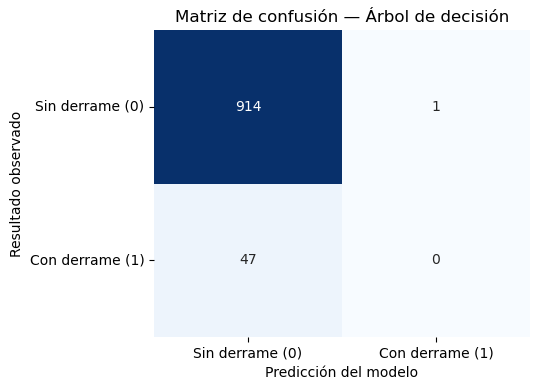

In [68]:
medicion_dt = evaluar_deteccion(predDT, "Árbol de decisión")

De 47 pacientes con derrame (Derrame = 1), el modelo detectó 0 y dejó pasar los 47. Entre los 915 pacientes sin derrame (Derrame = 0), clasificó correctamente a 914 y generó una falsa alarma. El modelo no cumplió el objetivo de detección porque no logró identificar ningún caso de derrame.

### 4. Modelo de Random Forest

Se incluyó para comprobar si combinar varios árboles reduce la dependencia de las divisiones de un solo árbol y mejora la detección de derrames en el mismo conjunto de prueba.

In [69]:
from pyspark.ml.classification import RandomForestClassifier

## Se instancia el modelo de Random Forest
rf = RandomForestClassifier(featuresCol='independientes', labelCol='Derrame')
## Se aplica el modelo de Random Forest sobre los datos de entrenamiento
modeloRF = rf.fit(train)

## Se evalúa el modelo de Random Forest

In [70]:
### Se hacen las predicciones sobre los datos de prueba en el modelo de Random Forest
predRF = modeloRF.transform(test)
## Se toman las probabilidades de resultados
resultadosRF = predRF.select(['probability', 'Derrame'])
## Se colectan los resultados
coleccResultadosRF = resultadosRF.collect()
## Se genera una lista
resultListaRF = [(float(i[0][0]), 1.0 - float(i[1])) for i in coleccResultadosRF]

## Se realizan las puntuaciones
puntuacionRF = sparkContextoDiaz.parallelize(resultListaRF)

#### Cálculo e impresión de métricas sobre resultados de prueba
metricasRF = Metricas(puntuacionRF)
ACURF = metricasRF.areaUnderROC
accuracyRF = MulticlassClassificationEvaluator(labelCol='Derrame', metricName='accuracy').evaluate(predRF)
precisRF = MulticlassClassificationEvaluator(labelCol='Derrame', metricName='weightedPrecision').evaluate(predRF)
recallRF = MulticlassClassificationEvaluator(labelCol='Derrame', metricName='weightedRecall').evaluate(predRF)

print(f"AUC-ROC : {round(ACURF, 2)}")
print(f"Accuracy : {round(accuracyRF, 2)}")
print(f"Precision : {round(precisRF, 2)}")
print(f"Recall : {round(recallRF, 2)}")

/mnt/sda1/Cluster/Spark/python/pyspark/sql/context.py:158: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


AUC-ROC : 0.84
Accuracy : 0.95
Precision : 0.9
Recall : 0.95


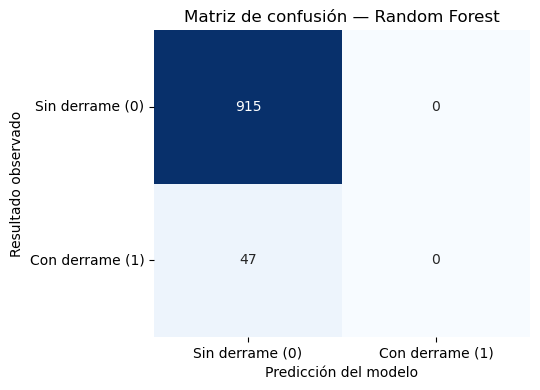

In [71]:
medicion_rf = evaluar_deteccion(predRF, "Random Forest")

De 47 pacientes con derrame (Derrame = 1), el modelo detectó 0 y dejó pasar los 47. Clasificó correctamente a los 915 pacientes sin derrame (Derrame = 0) y no generó falsas alarmas. El modelo no cumplió el objetivo de detección porque no logró identificar ningún caso de derrame.

### Comparación de la detección de derrames

In [72]:
comparacion_deteccion = pd.DataFrame([medicion_rl, medicion_nb, medicion_dt, medicion_rf])
comparacion_deteccion.set_index("Modelo").round(2)

,Casos reales de derrame,Derrames detectados (VP),Derrames omitidos (FN),Falsas alarmas (FP),Sin derrame bien clasificados (VN),Sensibilidad para derrame (%),Precisión para derrame (%)
Modelo,,,,,,,
Regresión logística,47,0,47,0,915,0.00,NaN
Naive Bayes,47,27,20,183,732,57.45,12.86
Árbol de decisión,47,0,47,1,914,0.00,0.00
Random Forest,47,0,47,0,915,0.00,NaN


## **Conclusiones**

- Durante el taller completamos los valores faltantes del BMI con el promedio del grupo de edad y género correspondiente. También convertimos las categorías de texto en números y reunimos las variables en un vector para usarlas en los modelos de Spark.
- Al comparar las gráficas de glucosa, vimos que en ambos grupos había una concentración de valores entre 60 y 120. En el grupo de pacientes con derrame también se observó un segundo pico más marcado entre 190 y 240.

- En el entrenamiento, 202 pacientes tenían registrado un derrame (4,87 %). En prueba, predecir siempre (Derrame = 0) habría acertado 915 de 962 casos (95,11 %), aunque habría omitido los 47 derrames.
- La regresión logística y Random Forest obtuvieron la mayor AUC-ROC (0,84 con el redondeo mostrado), pero con la regla de clasificación usada ambos omitieron los 47 derrames. El árbol de decisión también omitió los 47 casos y emitió una falsa alarma. Las matrices muestran por qué conviene evaluar la clase (Derrame = 1) de forma separada.
- Trabajar con DataFrames por etapas, desde los datos originales (df00) hasta el conjunto listo para modelar (df06), nos permitió revisar qué cambió en cada transformación. Si encontramos un problema en la imputación o en la codificación, podemos comparar las etapas e identificar dónde se introdujo antes de volver a entrenar los modelos.

### Modelo recomendado para el escenario del taller

En esta corrida escogeríamos **Naive Bayes** si nuestro objetivo es detectar la mayor cantidad posible de derrames. Fue el único de los cuatro modelos que identificó casos con (Derrame = 1). Detectó 27 de 47 (57,45 % de sensibilidad), dejó pasar 20 y generó 183 falsas alarmas. De los 210 casos que señaló, solo 27 tenían registrado un derrame (12,86 % de precisión).

Si hiciéramos este análisis con otros datos, probaríamos los cuatro modelos con las mismas particiones de entrenamiento y validación. Escogeríamos el modelo y el umbral según cuántos derrames detectan y cuántas falsas alarmas generan, y comprobaríamos esa elección con un conjunto de prueba reservado. Si se pensara en usar el modelo en un caso real, primero habría que validar su desempeño con datos del entorno donde se usaría (muestra pequeña), y revisar si la cantidad de errores es aceptable para ese uso.

In [ ]:
# Se detiene la sesión de Spark
sparkDiaz.stop()

![](https://www.appreciationatwork.com/wp-content/uploads/2018/01/thank-you.jpg)

I hope this tutorial was helpful.